# Segundo Parcial - INF672 Machine Learning

**Nombre:** Aviles Melchor Abimael Metzraim

**Asignatura:** INF672 - Machine Learning  

**Fecha:** 11/11/2026

In [34]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

nltk.download('stopwords', quiet=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 200)

RANDOM_STATE = 42

## 1. Carga y exploración

Leemos el archivo y revisamos nulos, clases, duplicados y longitud de las reseñas.

In [35]:
df = pd.read_csv('IMDB Dataset.csv')
print('Filas y columnas:', df.shape)
df.head()

Filas y columnas: (50000, 2)


,review,sentiment
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me...",positive
1,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire p...",positive
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted comedy. The plot is simplistic, but the dialogue i...",positive
3,Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap opera... and suddenl...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is a visually stunning film to watch. Mr. Mattei offers us a vivid portrait about human relations. This is a movie that seems to be telling us what mone...",positive


In [36]:
print('Valores nulos:')
print(df.isnull().sum())

print('\nDistribución de clases:')
print(df['sentiment'].value_counts())

n_dup = df.duplicated(subset='review').sum()
repetidas = df[df.duplicated(subset='review', keep=False)]
contradictorias = (repetidas.groupby('review')['sentiment'].nunique() > 1).sum()
print(f'\nReseñas duplicadas: {n_dup} (con etiquetas distintas: {contradictorias})')

df = df.drop_duplicates(subset='review').reset_index(drop=True)
print('\nDespués de eliminar duplicados:', len(df), 'reseñas')
print(df['sentiment'].value_counts())

Valores nulos:
review       0
sentiment    0
dtype: int64

Distribución de clases:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Reseñas duplicadas: 418 (con etiquetas distintas: 0)

Después de eliminar duplicados: 49582 reseñas
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


- No hay valores nulos.
- Las clases están **balanceadas** (mitad positivas, mitad negativas).
- Hay **418 reseñas repetidas** y las **eliminamos**: no aportan nada nuevo y, si una queda en entrenamiento y en prueba, el modelo se evalúa con algo que ya vio. Quedan 49 582 reseñas, todavía balanceadas.

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,24698.0,229.6,165.1,4.0,128.0,174.0,278.0,1522.0
positive,24884.0,233.1,177.7,10.0,125.0,172.0,284.0,2470.0


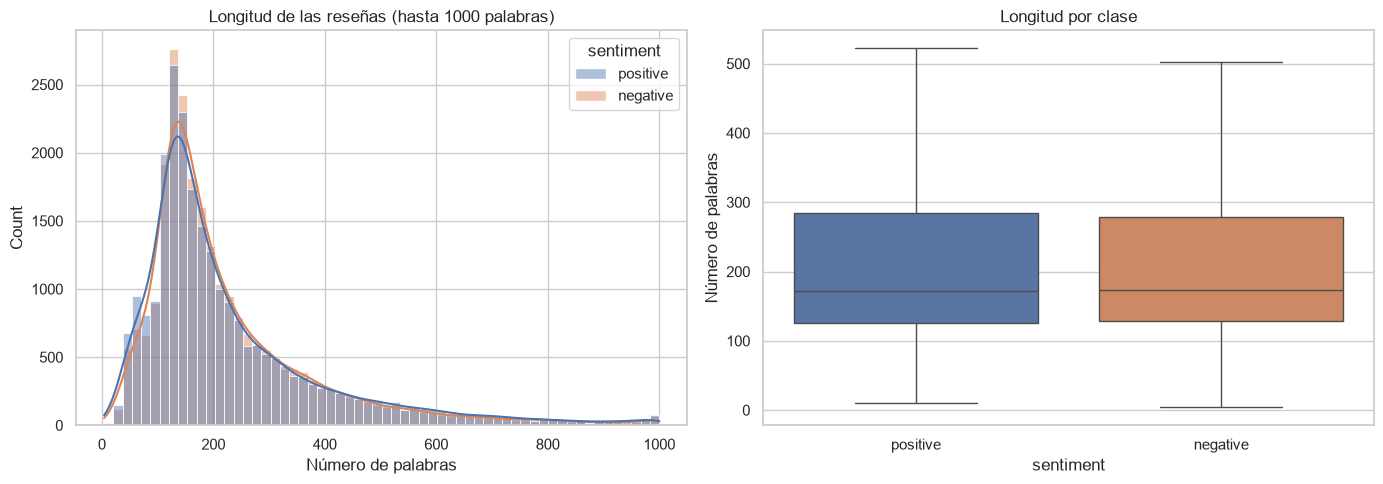

In [37]:
df['n_palabras'] = df['review'].str.split().str.len()
display(df.groupby('sentiment')['n_palabras'].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df[df['n_palabras'] <= 1000], x='n_palabras', hue='sentiment',
             bins=60, kde=True, alpha=0.45, ax=axes[0])
axes[0].set_title('Longitud de las reseñas (hasta 1000 palabras)')
axes[0].set_xlabel('Número de palabras')
sns.boxplot(data=df, x='sentiment', y='n_palabras', showfliers=False, ax=axes[1],
            hue='sentiment', palette=['#4c72b0', '#dd8452'], legend=False)
axes[1].set_title('Longitud por clase')
axes[1].set_ylabel('Número de palabras')
plt.tight_layout()
plt.show()

La mayoría de las reseñas tiene entre 125 y 280 palabras. Las positivas y las negativas miden casi lo mismo (mediana de 172 y 174), así que **la longitud no sirve para predecir el sentimiento**: el modelo tendrá que fijarse en las palabras.

## 2. Preprocesamiento

Revisamos algunas reseñas y contamos qué elementos "sucios" aparecen.

In [38]:
for i in [1, 5, 27]:
    print(f'--- Reseña {i} ({df.loc[i, "sentiment"]}) ---')
    print(df.loc[i, 'review'][:500], '\n')

patrones = {
    'Etiquetas HTML (<br />...)':    r'<[^>]+>',
    'URLs':                          r'http\S+|www\.\S+',
    'Números':                       r'\d',
    'Caracteres no ASCII':           r'[^\x00-\x7F]',
    'Emoticonos tipo :)':            r'[:;]-?[()DP]',
    "Contracciones negativas (n't)": r"n't",
}
pd.Series({k: df['review'].str.contains(p, regex=True).mean() * 100
           for k, p in patrones.items()}).round(2).sort_values(ascending=False).to_frame('% de reseñas')

--- Reseña 1 (positive) ---
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voices down pat too! You can truly see the seamless editing guided by the references to Williams' diary entries, not only is it well worth the watching but it is a terrificly writte 

--- Reseña 5 (positive) ---
Probably my all-time favorite movie, a story of selflessness, sacrifice and dedication to a noble cause, but it's not preachy or boring. It just never gets old, despite my having seen it some 15 or more times in the last 25 years. Paul Lukas' performance brings tears to my eyes, and Bette Davis, in one of her very few truly sympathetic roles, is a delight. The kids are, as grandma says, more like "dressed-up midgets" than children, but t

,% de reseñas
Contracciones negativas (n't),59.07
Etiquetas HTML (<br />...),58.42
Números,56.04
Caracteres no ASCII,9.33
Emoticonos tipo :),1.35
URLs,0.40


**Qué limpiamos:**

- **Etiquetas HTML** (58 %, casi todas `<br />`): se eliminan.
- **Números, URLs, puntuación y símbolos**: se eliminan, solo dejamos letras.
- **Contracciones** como `don't` (59 %): las pasamos a `do not` antes de quitar la puntuación, para no perder la negación.
- Todo en minúsculas, y al final stemming (`movie` → `movi`).

**Stopwords:** NLTK incluye *not*, *no* y *but*. Si las quitamos, *"good"* y *"not good"* quedan iguales. Por eso **conservamos** *no, not, nor, but, against, very, too, only, few, more, most*, y quitamos el resto (*the, a, is...*).

Trabajamos con una **muestra de 5 000 reseñas** (2 500 de cada clase).

In [39]:
STOPWORDS_NLTK = set(stopwords.words('english'))
PALABRAS_A_CONSERVAR = {'no', 'not', 'nor', 'but', 'against', 'very', 'too', 'only', 'few', 'more', 'most'}
STOPWORDS_SENTIMIENTO = STOPWORDS_NLTK - PALABRAS_A_CONSERVAR

stemmer = PorterStemmer()

def preprocesar(texto, lista_stopwords=STOPWORDS_SENTIMIENTO):
    texto = texto.lower()
    texto = re.sub(r'<[^>]+>', ' ', texto)              # etiquetas HTML
    texto = re.sub(r'http\S+|www\.\S+', ' ', texto)      # URLs
    texto = re.sub(r"won't", 'will not', texto)
    texto = re.sub(r"can't", 'can not', texto)
    texto = re.sub(r"n't", ' not', texto)                # don't -> do not
    texto = re.sub(r'[^a-z\s]', ' ', texto)              # solo letras
    palabras = texto.split()
    palabras = [stemmer.stem(p) for p in palabras
                if p not in lista_stopwords and len(p) > 1]
    return ' '.join(palabras)

frase = "This movie is NOT good.<br /><br />I didn't like the ending, but the actors were great!!"
print('Original:                 ', frase)
print('Conservando negaciones:   ', preprocesar(frase))
print('Quitando TODAS stopwords: ', preprocesar(frase, STOPWORDS_NLTK))

Original:                  This movie is NOT good.<br /><br />I didn't like the ending, but the actors were great!!
Conservando negaciones:    movi not good not like end but actor great
Quitando TODAS stopwords:  movi good like end actor great


In [40]:
N_MUESTRA = 5000

muestra = (df.groupby('sentiment', group_keys=False)
             .sample(n=N_MUESTRA // 2, random_state=RANDOM_STATE)
             .reset_index(drop=True))

muestra['limpia'] = muestra['review'].apply(preprocesar)
muestra['limpia_sw_todas'] = muestra['review'].apply(lambda t: preprocesar(t, STOPWORDS_NLTK))
muestra['y'] = (muestra['sentiment'] == 'positive').astype(int)

muestra[['review', 'limpia', 'sentiment']].head(3)

,review,limpia,sentiment
0,"I usually much prefer French movies over American ones, with explosions and car chases, but this movie was very disappointing. There is no way to write a spoiler because nothing really happens. Th...",usual much prefer french movi american one explos car chase but movi veri disappoint no way write spoiler noth realli happen french coupl live lisbon year return pari friend wed announc anoth frie...,negative
1,"This movie lacked... everything: story, acting, surprise, ingenuity and a soul. Fifteen minutes in, I was staring at the screen saying, ""How could all of these guys get together and consider thems...",movi lack everyth stori act surpris ingenu soul fifteen minut stare screen say could guy get togeth consid friend even without girl anoth fifteen minut pray much amanda peet possibl bad movi quiet...,negative
2,"Bonjour Tristesse covers similar ground as 'The Member of the Wedding.' to wit, a possessive daughter tries to prevent a relationship from forming between a beloved family member and an interloper...",bonjour tristess cover similar ground member wed wit possess daughter tri prevent relationship form belov famili member interlop critic love member wed find juli harri jumbo drag adenoid sceneri c...,negative


## 3. División de los datos

80 % entrenamiento y 20 % prueba, con `stratify` y `random_state=42`.

**¿Por qué el vectorizador se ajusta solo con el entrenamiento?** Porque al hacer `fit` aprende el vocabulario. Si incluyera la prueba, el modelo ya "conocería" esas reseñas y los resultados saldrían mejores de lo real (**fuga de datos**). Por eso: `fit_transform` en entrenamiento y solo `transform` en prueba.

In [41]:
X = muestra[['review', 'limpia', 'limpia_sw_todas']]
y = muestra['y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Entrenamiento:', len(X_train), '| Prueba:', len(X_test))

Entrenamiento: 4000 | Prueba: 1000


## 4. Vectorización

- **Modelo A, Bag of Words:** cuenta cuántas veces aparece cada palabra en la reseña.
- **Modelo B, TF-IDF:** también cuenta, pero le da un peso a cada palabra:
  - **TF:** cuántas veces sale la palabra en la reseña.
  - **IDF:** qué tan rara es entre todas las reseñas. Las que salen en casi todas (como "film") valen poco.

  Así, una palabra pesa más si es frecuente en esa reseña pero rara en las demás.

In [42]:
bow = CountVectorizer()
Xtr_bow = bow.fit_transform(X_train['limpia'])   # fit solo con entrenamiento
Xte_bow = bow.transform(X_test['limpia'])

tfidf = TfidfVectorizer()
Xtr_tfidf = tfidf.fit_transform(X_train['limpia'])
Xte_tfidf = tfidf.transform(X_test['limpia'])

print('Bag of Words:', Xtr_bow.shape)
print('TF-IDF:      ', Xtr_tfidf.shape)

Bag of Words: (4000, 23215)
TF-IDF:       (4000, 23215)


**Experimento con parámetros.** Probamos `max_features` (limita el número de palabras), `min_df` (quita palabras muy raras) y `ngram_range=(1,2)` (añade pares de palabras, como `not good`). Comparamos con validación cruzada de 5 partes sobre el entrenamiento, sin tocar la prueba.

Exactitud (CV 5)         Tamaño vocabulario  \
Vectorizador                              BoW  TF-IDF                BoW   
Configuración                                                              
Por defecto                            0.8465  0.8565              23215   
max_features=1000                      0.8155  0.8445               1000   
max_features=5000                      0.8432  0.8542               5000   
min_df=2                               0.8458  0.8570              13050   
min_df=5                               0.8445  0.8542               6934   
ngram_range=(1,2)                      0.8562  0.8512             351218   
ngram_range=(1,2) + min_df=2           0.8580  0.8563              60503   

                                      
Vectorizador                  TF-IDF  
Configuración                         
Por defecto                    23215  
max_features=1000               1000  
max_features=5000               5000  
min_df=2                       13050  
min_df=5                        6934  
ngram_range=(1,2)             351218  
ngram_range=(1,2) + min_df=2   60503

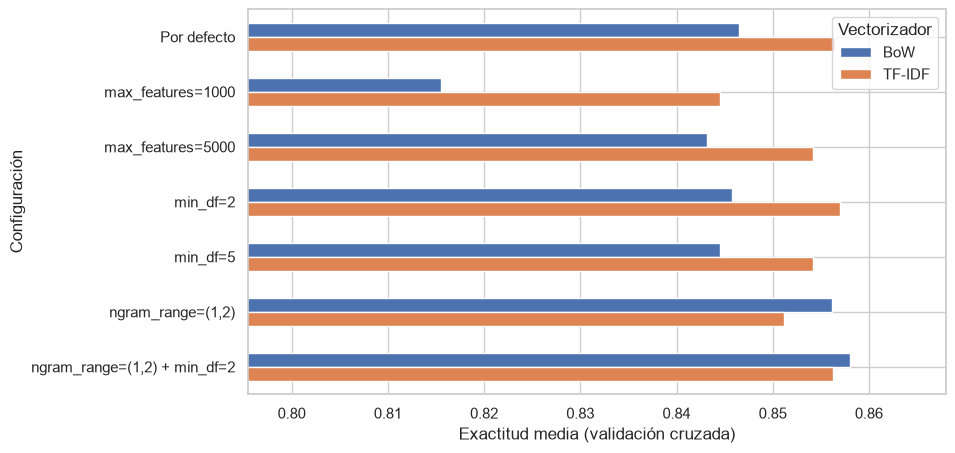

Mejor para BoW: ngram_range=(1,2) + min_df=2 (0.858)
Mejor para TF-IDF: min_df=2 (0.857)


In [43]:
VECTORIZADORES = {'BoW': CountVectorizer, 'TF-IDF': TfidfVectorizer}

configs = [
    ('Por defecto',                  {}),
    ('max_features=1000',            {'max_features': 1000}),
    ('max_features=5000',            {'max_features': 5000}),
    ('min_df=2',                     {'min_df': 2}),
    ('min_df=5',                     {'min_df': 5}),
    ('ngram_range=(1,2)',            {'ngram_range': (1, 2)}),
    ('ngram_range=(1,2) + min_df=2', {'ngram_range': (1, 2), 'min_df': 2}),
]

filas = []
for nombre, params in configs:
    for tipo, Vec in VECTORIZADORES.items():
        n_vocab = len(Vec(**params).fit(X_train['limpia']).vocabulary_)
        pipe = make_pipeline(Vec(**params), LogisticRegression(max_iter=1000))
        acc = cross_val_score(pipe, X_train['limpia'], y_train, cv=5, scoring='accuracy').mean()
        filas.append({'Configuración': nombre, 'Vectorizador': tipo,
                      'Tamaño vocabulario': n_vocab, 'Exactitud CV': round(acc, 4), 'params': params})

experimentos = pd.DataFrame(filas)
orden = [c[0] for c in configs]
tabla_acc = experimentos.pivot(index='Configuración', columns='Vectorizador', values='Exactitud CV').reindex(orden)
tabla_voc = experimentos.pivot(index='Configuración', columns='Vectorizador', values='Tamaño vocabulario').reindex(orden)
display(pd.concat({'Exactitud (CV 5)': tabla_acc, 'Tamaño vocabulario': tabla_voc}, axis=1))

ax = tabla_acc.plot(kind='barh', figsize=(9, 5), color=['#4c72b0', '#dd8452'])
ax.set_xlim(tabla_acc.min().min() - 0.02, tabla_acc.max().max() + 0.01)
ax.set_xlabel('Exactitud media (validación cruzada)')
ax.invert_yaxis()
plt.show()

mejores_params = {}
for tipo in VECTORIZADORES:
    sub = experimentos[experimentos['Vectorizador'] == tipo]
    fila = sub.loc[sub['Exactitud CV'].idxmax()]
    mejores_params[tipo] = fila['params']
    print(f"Mejor para {tipo}: {fila['Configuración']} ({fila['Exactitud CV']})")

- **`max_features=1000`** es lo que más empeora (BoW baja de 0,847 a 0,816).
- **`min_df`** reduce mucho el vocabulario (de 23 215 a 6 934 con `min_df=5`) casi sin perder exactitud.
- **Bigramas:** ayudan a Bag of Words, pero no a TF-IDF.
- Las mejores versiones de cada uno quedan casi empatadas (0,858 vs 0,857).

Ahora comprobamos si conservar las negaciones fue buena idea:

In [44]:
resultados_sw = {}
for nombre, columna in [('Quitando TODAS las stopwords', 'limpia_sw_todas'),
                        ('Conservando negaciones', 'limpia')]:
    for tipo in VECTORIZADORES:
        pipe = make_pipeline(VECTORIZADORES[tipo](**mejores_params[tipo]), LogisticRegression(max_iter=1000))
        acc = cross_val_score(pipe, X_train[columna], y_train, cv=5, scoring='accuracy').mean()
        resultados_sw.setdefault(nombre, {})[tipo] = round(acc, 4)

pd.DataFrame(resultados_sw).T

,BoW,TF-IDF
Quitando TODAS las stopwords,0.8542,0.8575
Conservando negaciones,0.8580,0.8570


Con Bag of Words, conservar las negaciones mejora un poco (0,854 → 0,858). Con TF-IDF quedan empatadas. Como no empeora y tiene lógica, **mantenemos la decisión**.

## 5. Entrenamiento y evaluación

Entrenamos una Regresión Logística con cada representación y evaluamos en la prueba.

- **Exactitud:** % de reseñas bien clasificadas.
- **Precisión:** de las que dijo positivas, cuántas lo eran.
- **Recall:** de las positivas reales, cuántas encontró.
- **F1:** combina precisión y recall.

===== Modelo A - Bag of Words =====
              precision    recall  f1-score   support

    negative      0.859     0.856     0.858       500
    positive      0.857     0.860     0.858       500

    accuracy                          0.858      1000
   macro avg      0.858     0.858     0.858      1000
weighted avg      0.858     0.858     0.858      1000

===== Modelo B - TF-IDF =====
              precision    recall  f1-score   support

    negative      0.874     0.850     0.862       500
    positive      0.854     0.878     0.866       500

    accuracy                          0.864      1000
   macro avg      0.864     0.864     0.864      1000
weighted avg      0.864     0.864     0.864      1000



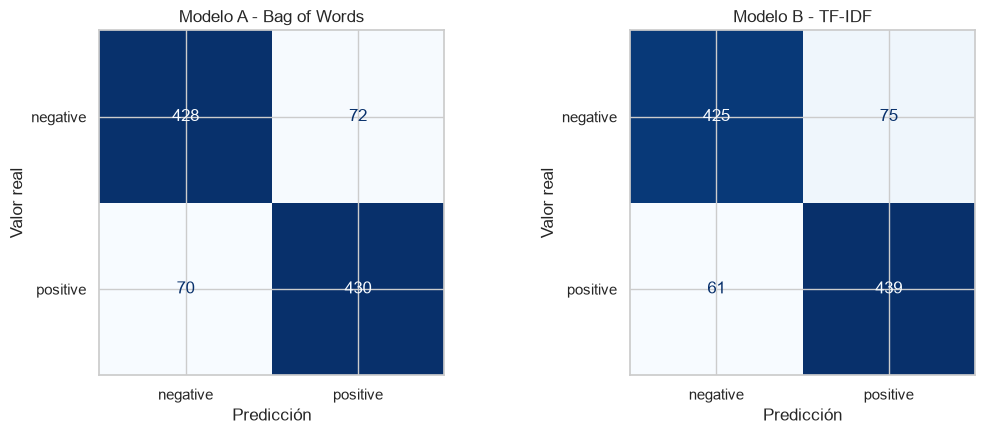

Modelo elegido (mayor F1): Modelo B - TF-IDF


,Configuración,Exactitud,Precisión,Recall,F1
Modelo A - Bag of Words,"{'ngram_range': (1, 2), 'min_df': 2}",0.858,0.8566,0.86,0.8583
Modelo B - TF-IDF,{'min_df': 2},0.864,0.8541,0.878,0.8659


In [45]:
NOMBRES = {'BoW': 'Modelo A - Bag of Words', 'TF-IDF': 'Modelo B - TF-IDF'}
modelos, resultados, matrices = {}, {}, {}

for tipo, Vec in VECTORIZADORES.items():
    vec = Vec(**mejores_params[tipo])
    Xtr = vec.fit_transform(X_train['limpia'])
    Xte = vec.transform(X_test['limpia'])
    clf = LogisticRegression(max_iter=1000).fit(Xtr, y_train)
    pred = clf.predict(Xte)

    nombre = NOMBRES[tipo]
    modelos[nombre] = (vec, clf)
    matrices[nombre] = confusion_matrix(y_test, pred)
    resultados[nombre] = {
        'Configuración': str(mejores_params[tipo]) if mejores_params[tipo] else 'por defecto',
        'Exactitud': round(accuracy_score(y_test, pred), 4),
        'Precisión': round(precision_score(y_test, pred), 4),
        'Recall':    round(recall_score(y_test, pred), 4),
        'F1':        round(f1_score(y_test, pred), 4),
    }
    print(f'===== {nombre} =====')
    print(classification_report(y_test, pred, target_names=['negative', 'positive'], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nombre, cm) in zip(axes, matrices.items()):
    ConfusionMatrixDisplay(cm, display_labels=['negative', 'positive']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(nombre)
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Valor real')
plt.tight_layout()
plt.show()

tabla_resultados = pd.DataFrame(resultados).T
mejor = tabla_resultados['F1'].astype(float).idxmax()
print('Modelo elegido (mayor F1):', mejor)
tabla_resultados

Los dos aciertan cerca del 86 %. **Elegimos TF-IDF**: tiene mejor exactitud (86,4 % vs 85,8 %) y F1 (0,866 vs 0,858), y usa muchas menos palabras (13 050 frente a más de 60 000). La diferencia es pequeña, pero TF-IDF es más simple.

En la matriz de confusión, TF-IDF se equivoca un poco más diciendo "positivo" (75 falsos positivos y 61 falsos negativos).

## 6. Interpretación del modelo

Cada palabra tiene un coeficiente: si es positivo empuja hacia *positive* y si es negativo, hacia *negative*.

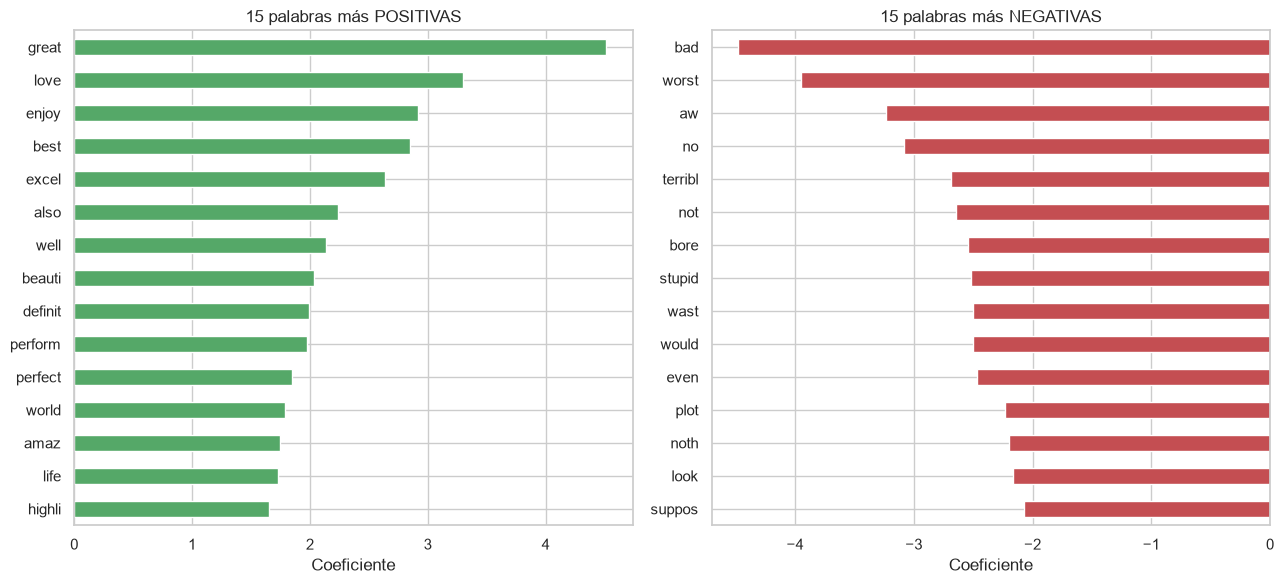

In [46]:
vec_mejor, clf_mejor = modelos[mejor]
coeficientes = pd.Series(clf_mejor.coef_[0], index=vec_mejor.get_feature_names_out())
top_pos = coeficientes.sort_values(ascending=False).head(15)
top_neg = coeficientes.sort_values().head(15)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
top_pos.sort_values().plot(kind='barh', color='#55a868', ax=axes[0])
axes[0].set_title('15 palabras más POSITIVAS')
top_neg.sort_values(ascending=False).plot(kind='barh', color='#c44e52', ax=axes[1])
axes[1].set_title('15 palabras más NEGATIVAS')
for ax in axes:
    ax.set_xlabel('Coeficiente')
plt.tight_layout()
plt.show()

**Sí tienen sentido.** Positivas: `great`, `love`, `enjoy`, `best`, `excel` (*excellent*), `perfect`. Negativas: `bad`, `worst`, `aw` (*awful*), `terribl`, `bore`, `wast` (*waste*).

`no` y `not` salen entre las más negativas, lo que confirma que valía la pena conservarlas. Otras como `would`, `plot` o `suppos` no son opiniones, pero aparecen mucho en quejas ("it was *supposed* to be funny").

**Reseñas propias:** una positiva, una negativa y una sarcástica.

In [47]:
mis_resenas = {
    'Positiva': "This film was absolutely wonderful. The acting was brilliant, the story kept me hooked "
                "from start to finish and the soundtrack was beautiful. I would definitely watch it again.",
    'Negativa': "A complete waste of time. The plot made no sense, the dialogue was awful and I almost "
                "fell asleep halfway through. One of the worst movies I have ever seen.",
    'Sarcástica': "Oh great, another two hours of my life I will never get back. Brilliant acting, "
                  "if you enjoy watching paint dry. Truly a masterpiece of boredom.",
}

probas = clf_mejor.predict_proba(vec_mejor.transform([preprocesar(t) for t in mis_resenas.values()]))
pd.DataFrame({
    'Tipo': list(mis_resenas.keys()),
    'P(negative)': probas[:, 0].round(3),
    'P(positive)': probas[:, 1].round(3),
    'Predicción': np.where(probas[:, 1] >= 0.5, 'positive', 'negative'),
})

,Tipo,P(negative),P(positive),Predicción
0,Positiva,0.266,0.734,positive
1,Negativa,0.977,0.023,negative
2,Sarcástica,0.258,0.742,positive


- **Positiva:** acierta (0,73).
- **Negativa:** acierta con mucha seguridad (0,98).
- **Sarcástica:** **falla**, la da como positiva (0,74). Usa palabras positivas de forma irónica (`great`, `brilliant`, `enjoy`) y el modelo no entiende el tono.

**Reseñas mal clasificadas:** buscamos los dos errores en los que el modelo estaba más seguro.

In [48]:
proba_test = clf_mejor.predict_proba(vec_mejor.transform(X_test['limpia']))[:, 1]
analisis = X_test.assign(real=y_test, proba=proba_test, pred=(proba_test >= 0.5).astype(int))
errores = analisis[analisis['real'] != analisis['pred']].copy()
errores['seguridad'] = (errores['proba'] - 0.5).abs()
print(f'Errores: {len(errores)} de {len(analisis)}')

falso_positivo = errores[errores['real'] == 0].sort_values('seguridad', ascending=False).iloc[0]
falso_negativo = errores[errores['real'] == 1].sort_values('seguridad', ascending=False).iloc[0]

def palabras_clave(texto_limpio, n=6):
    contrib = pd.Series(vec_mejor.transform([texto_limpio]).toarray()[0] * clf_mejor.coef_[0],
                        index=vec_mejor.get_feature_names_out())
    contrib = contrib[contrib != 0]
    return (list(contrib.sort_values(ascending=False).head(n).index),
            list(contrib.sort_values().head(n).index))

for titulo, fila in [('FALSO POSITIVO (real: negative)', falso_positivo),
                     ('FALSO NEGATIVO (real: positive)', falso_negativo)]:
    pos, neg = palabras_clave(fila['limpia'])
    print('\n' + '=' * 90)
    print(f"{titulo} | P(positive) = {fila['proba']:.3f}")
    print('Palabras que empujan a positivo:', pos)
    print('Palabras que empujan a negativo:', neg)
    print('=' * 90)
    print(re.sub(r'<[^>]+>', ' ', fila['review']))

Errores: 136 de 1000

FALSO POSITIVO (real: negative) | P(positive) = 0.761
Palabras que empujan a positivo: ['excel', 'winter', 'today', 'show', 'although', 'avail']
Palabras que empujan a negativo: ['reason', 'funni', 'rest', 'offens', 'make', 'posit']
Rounding out the 1929-30 all-talkie "Our Gang" release schedule, "A Tough Winter" features two storylines. First, Wheezer and Mary Ann, home alone on a wintry day, decide to make some taffy. Little Wheezer relays the directions to Mary Ann from a radio cooking show. The problem: Wheezer relays information from different shows and Mary Ann ends up putting soap in the mix! Funny moments occur when the rest of the Gang shows up to pull the taffy - and end up getting it all over the house!  The second storyline deals with Stepin Fetchit, a neighbor/handyman of the Gang, and his interactions with the Gang.  "A Tough Winter," to my knowledge, has never been shown on television, although it is available on home video. The reason for this is t

**¿Por qué falló?**

- **Falso positivo:** la reseña le pone **3 de 10** a un corto antiguo, pero casi todo el texto es descriptivo y dice que otras películas son *"excellent"*. La palabra que más empuja a positivo es justamente `excel`, aunque no habla de esta película. Además, el "3 out of 10" se perdió al quitar los números.
- **Falso negativo:** es una reseña tibia. Dice que la película está bien, pero casi todo el texto habla de lo que le falta (*"nothing"*, *"fail"*, *"lack"*). El modelo ve más palabras de crítica que de elogio.

El modelo no entiende la reseña, solo suma el peso de sus palabras.

## 7. Conclusiones

1. El proceso de clase sirvió para este problema, pero hubo que adaptarlo: quitar `<br />`, eliminar duplicados y tratar las contracciones.
2. En sentimiento, las stopwords como *not* o *but* importan. Conservarlas no empeoró el modelo, y `no` y `not` resultaron palabras importantes.
3. El vectorizador se ajusta solo con el entrenamiento para evitar la fuga de datos.
4. **TF-IDF fue el mejor modelo** (86,4 % de exactitud, F1 0,866), aunque por poco frente a Bag of Words. `min_df` redujo mucho el vocabulario sin perder exactitud.
5. Las palabras que aprendió tienen sentido (*great, love* frente a *bad, worst*).
6. **Limitaciones:** no entiende el sarcasmo ni las reseñas mixtas. Se podría mejorar usando todo el dataset, conservando notas como "3/10" o probando modelos que entiendan el contexto.